# LeMat-Rho dataset diversity

Figures characterising the LeMat-Rho dataset: forces, stresses, structures, compositions, PCA of descriptors and Bader properties.

Run the notebook top to bottom. Each publication figure is saved as a PDF in the notebook directory:

| Section | Output file |
|---|---|
| Forces | `force_magnitude_histogram.pdf` |
| Stresses | `stress_magnitude_histogram.pdf` |
| Structure | `structure_distributions.pdf` |
| Composition | `heatmap_element_percentage.pdf`, `element_cooccurrence_heatmap.pdf`, `metal_site_percentage_distribution.pdf`, `smact_validity_option_comparison.pdf` |
| PCA | `pca_charge_density_bader_comparison.pdf` |
| Bader charges | `bader_charge_histogram.pdf`, `bader_charge_grid.pdf` |

Cells marked *exploratory* only display a plot and save nothing.

In [60]:
# Requires: pandas, matplotlib, pymatgen, pymatviz (+ kaleido for PDF export), scikit-learn, smact, datasets
import ast
import os
from collections import Counter
from functools import lru_cache
from itertools import combinations
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import smact
from pymatgen.core import Element
from pymatgen.symmetry.groups import SpaceGroup
from pymatviz.ptable import ptable_heatmap_plotly
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from smact.screening import smact_validity


def set_publication_style():
    # Shared style for all figures.
    cm = 1 / 2.54
    mpl.rcParams.update(
        {
            "figure.figsize": (19 * cm, 6 * cm),
            "figure.dpi": 300,
            "font.family": "serif",
            "font.size": 8,
            "axes.labelsize": 8,
            "axes.titlesize": 8,
            "xtick.labelsize": 7,
            "ytick.labelsize": 7,
            "legend.fontsize": 7,
            "lines.linewidth": 1.2,
            "lines.markersize": 4,
            "axes.linewidth": 0.8,
            "axes.grid": True,
            "grid.linewidth": 0.5,
            "grid.alpha": 0.5,
            "xtick.direction": "out",
            "ytick.direction": "out",
            "xtick.minor.visible": True,
            "ytick.minor.visible": True,
            "xtick.minor.size": 2,
            "ytick.minor.size": 2,
            "xtick.minor.width": 0.6,
            "ytick.minor.width": 0.6,
            "xtick.major.size": 3,
            "ytick.major.size": 3,
            "xtick.major.width": 0.8,
            "ytick.major.width": 0.8,
            "legend.frameon": False,
            "savefig.bbox": "tight",
            "savefig.pad_inches": 0.02,
        }
    )


set_publication_style()

# Colours for the 80th / 98th / 99th percentile markers and other three-colour plots.
PURPLES = ["fuchsia", "mediumorchid", "mediumpurple"]


def flatten_numeric(value):
    # Flatten nested lists/arrays (as stored in the parquet) into a 1D float array.
    try:
        return np.asarray(value, dtype=float).ravel()
    except (ValueError, TypeError):
        return np.concatenate([flatten_numeric(item) for item in value])

## Load the dataset

In [3]:
PARQUET_NAME = "materials_dataset_LeMatRho_final.parquet"


def find_local_parquet():
    # Look in $MATERIALS_DATASET_PARQUET, the notebook directory, then the cwd and its parents.
    env_path = os.environ.get("MATERIALS_DATASET_PARQUET")
    if env_path and Path(env_path).expanduser().is_file():
        return Path(env_path).expanduser()

    notebook_file = os.environ.get("__vsc_ipynb_file__")
    if notebook_file and (Path(notebook_file).parent / PARQUET_NAME).is_file():
        return Path(notebook_file).parent / PARQUET_NAME

    here = Path.cwd().resolve()
    for directory in [here, *here.parents[:5]]:
        if (directory / PARQUET_NAME).is_file():
            return directory / PARQUET_NAME
    return None


parquet_path = find_local_parquet()
if parquet_path is not None:
    df = pd.read_parquet(parquet_path)
    print(f"Loaded {len(df):,} rows from {parquet_path}")
else:
    from datasets import load_dataset

    df = load_dataset("LeMaterial/LeMat-Rho")["train"].to_pandas()
    print(f"Loaded {len(df):,} rows from Hugging Face (LeMaterial/LeMat-Rho)")

Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/33 [00:00<?, ?it/s]

Loaded 69,117 rows from Hugging Face (LeMaterial/LeMat-Rho)


In [4]:
print(df.columns.tolist())
print(df.iloc[0])

# Source database of each structure (agm, mp, oqmd), taken from the ID prefix.
source = (
    df["immutable_id"]
    .astype("string")
    .str.extract(r"^([A-Za-z]+)", expand=False)
    .str.lower()
    .fillna("unknown")
)
print(source.value_counts())

['elements', 'nsites', 'chemical_formula_anonymous', 'chemical_formula_reduced', 'chemical_formula_descriptive', 'nelements', 'dimension_types', 'nperiodic_dimensions', 'lattice_vectors', 'immutable_id', 'cartesian_site_positions', 'species', 'species_at_sites', 'last_modified', 'elements_ratios', 'stress_tensor', 'energy', 'energy_corrected', 'magnetic_moments', 'forces', 'total_magnetization', 'charges', 'dos_ef', 'functional', 'cross_compatibility', 'bawl_fingerprint', 'space_group_it_number', 'compressed_charge_density', 'compressed_aeccar0', 'compressed_aeccar1', 'compressed_aeccar2', 'charge_density_grid_shape', 'bader_charges', 'bader_atomic_volume', 'ddec6_charges']
elements                                                              [Be, N, Tb]
nsites                                                                          4
chemical_formula_anonymous                                                   A2BC
chemical_formula_reduced                                               

## Force distribution & Stress tensor

Maximum summed shear asymmetry: 2.79 kB


/var/folders/br/t_m09nrx5095w0jym2vqnbyr0000gp/T/ipykernel_5374/2208399524.py:66: UserWarning:

The figure layout has changed to tight



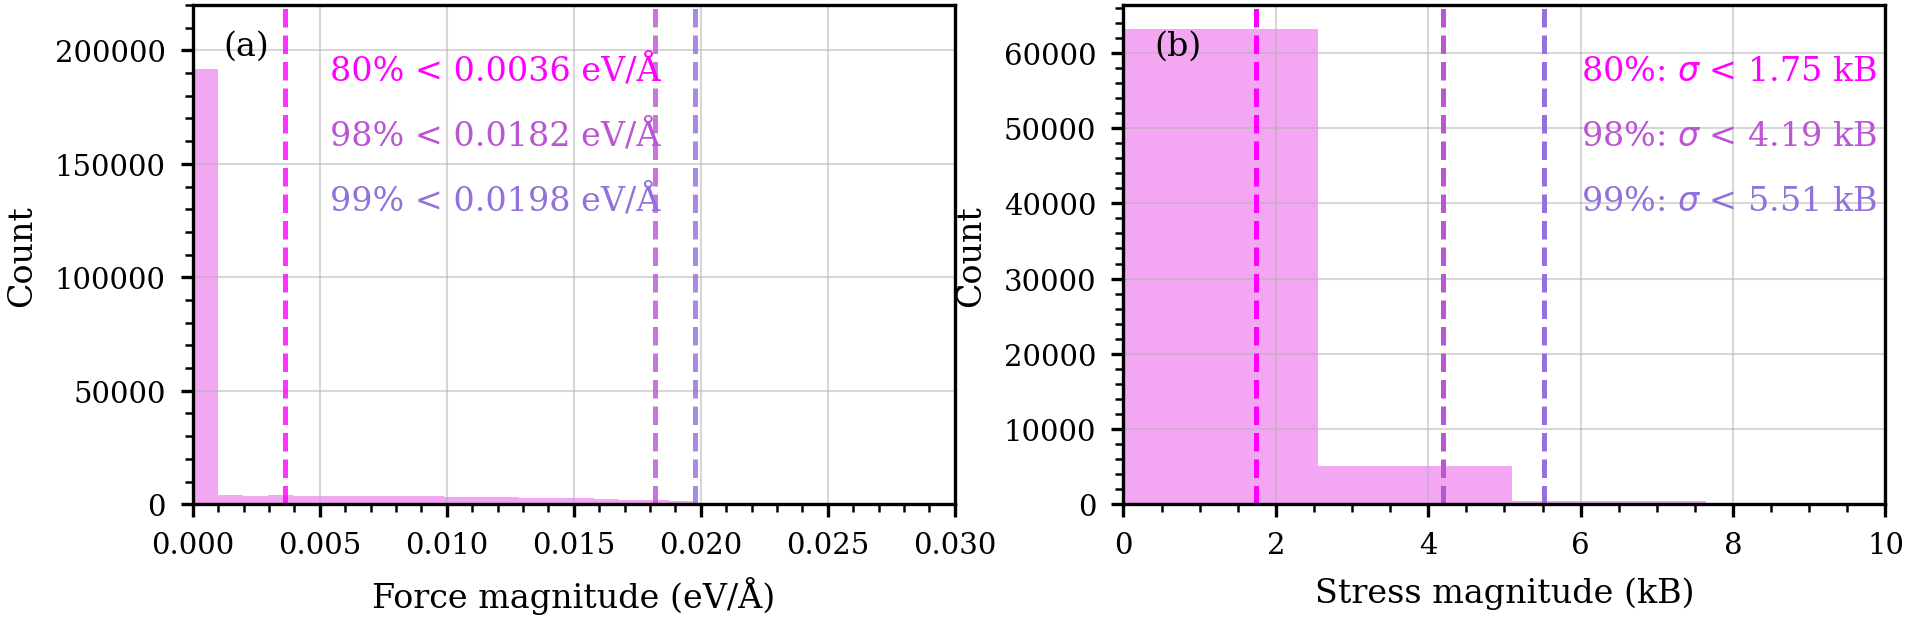

In [61]:
force_magnitude = np.concatenate(
    [
        np.linalg.norm(flatten_numeric(forces).reshape(-1, 3), axis=1)
        for forces in df["forces"].dropna()
    ]
)

stress_tensors = np.stack(
    [
        flatten_numeric(stress).reshape(3, 3)
        for stress in df["stress_tensor"].dropna()
    ]
)
shear_asymmetry = (
    np.abs(stress_tensors[:, 0, 1] - stress_tensors[:, 1, 0])
    + np.abs(stress_tensors[:, 0, 2] - stress_tensors[:, 2, 0])
    + np.abs(stress_tensors[:, 1, 2] - stress_tensors[:, 2, 1])
)
print(f"Maximum summed shear asymmetry: {shear_asymmetry.max():.3g} kB")

stress_magnitude = np.linalg.norm(stress_tensors, axis=(1, 2))

fig, (ax_force, ax_stress) = plt.subplots(
    1, 2, constrained_layout=True
)

# Left panel: force magnitude
ax_force.hist(force_magnitude, bins=100, color="violet", alpha=0.7)

for y, percentile, color in zip((0.85, 0.72, 0.59), (80, 98, 99), PURPLES):
    value = np.percentile(force_magnitude, percentile)
    ax_force.axvline(value, color=color, linestyle="--", alpha=0.8)
    ax_force.text(
        0.18, y, f"{percentile}% < {value:.4f} eV/Å",
        transform=ax_force.transAxes, color=color,
    )

ax_force.set(
    xlim=(0, 0.03), ylim=(0, 220000),
    xlabel="Force magnitude (eV/Å)", ylabel="Count",
)

# Right panel: stress magnitude
ax_stress.hist(stress_magnitude, bins=60, color="violet", alpha=0.7)

for y, percentile, color in zip((0.85, 0.72, 0.59), (80, 98, 99), PURPLES):
    value = np.percentile(stress_magnitude, percentile)
    ax_stress.axvline(value, color=color, linestyle="--")
    ax_stress.text(
        0.6, y, rf"{percentile}%: $\sigma$ < {value:.2f} kB",
        transform=ax_stress.transAxes, color=color,
    )

ax_stress.set(
    xlim=(0, 10), xlabel="Stress magnitude (kB)", ylabel="Count",
)

# Panel labels positioned consistently using axes coordinates
for ax, label in zip((ax_force, ax_stress), ("(a)", "(b)")):
    ax.text(
        0.04, 0.95, label,
        transform=ax.transAxes, ha="left", va="top",
    )

fig.savefig("force_stress_histograms.pdf", bbox_inches="tight")
plt.tight_layout()
plt.show()

## Structural diversity

In [7]:
# Per-structure table used by the structure and composition sections.
structure_df = df[["nsites", "nelements", "space_group_it_number"]].astype(int)
structure_df["elements"] = df["elements"].apply(lambda values: tuple(sorted(values)))

crystal_systems = {
    number: SpaceGroup.from_int_number(number).crystal_system
    for number in structure_df["space_group_it_number"].unique()
}
structure_df["crystal_system"] = structure_df["space_group_it_number"].map(crystal_systems)


def lattice_features(vectors):
    matrix = flatten_numeric(vectors).reshape(3, 3)
    a, b, c = matrix

    def angle(u, v):
        cosine = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
        return np.degrees(np.arccos(np.clip(cosine, -1.0, 1.0)))

    return pd.Series(
        {
            "a": np.linalg.norm(a),
            "b": np.linalg.norm(b),
            "c": np.linalg.norm(c),
            "alpha": angle(b, c),
            "beta": angle(a, c),
            "gamma": angle(a, b),
            "volume": abs(np.linalg.det(matrix)),
        }
    )


lattice_df = df["lattice_vectors"].apply(lattice_features)
structure_df = structure_df.join(lattice_df)
structure_df.head()

,nsites,nelements,space_group_it_number,elements,crystal_system,a,b,c,alpha,beta,gamma,volume
0,4,3,166,"(Be, N, Tb)",trigonal,3.515172,3.515172,5.615706,71.761277,71.761277,60.0,56.032043
1,4,3,166,"(Be, N, Nd)",trigonal,3.645854,3.645854,5.750902,71.519550,71.519550,60.0,61.607238
2,4,3,166,"(Be, I, P)",trigonal,3.648746,3.648746,6.773191,74.374287,74.374287,60.0,74.219656
3,4,3,166,"(Np, Sb, Ta)",trigonal,3.139829,3.139829,11.213357,81.951924,81.951924,60.0,94.477357
4,4,3,166,"(Ac, Al, Au)",trigonal,4.358355,4.358355,6.391339,70.064755,70.064755,60.0,96.648533


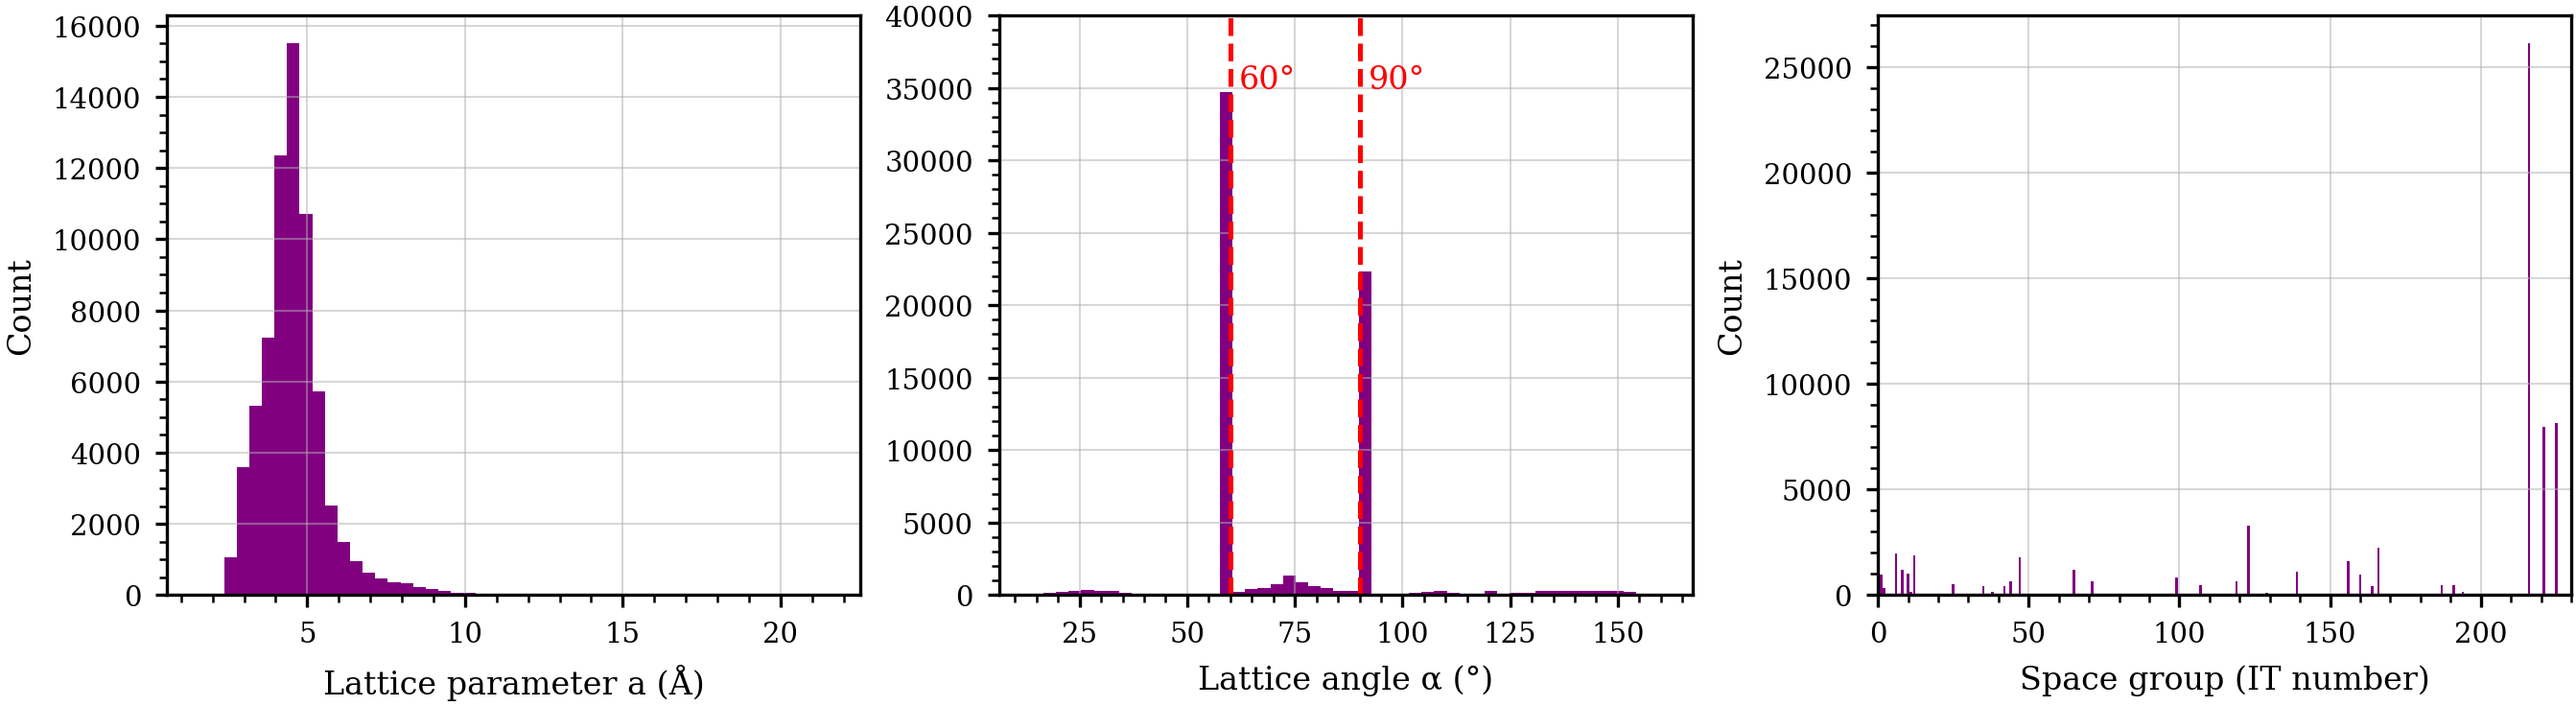

In [8]:
# Exploratory: lattice parameter a, lattice angle alpha and space-group distributions.
fig, (ax_a, ax_alpha, ax_sg) = plt.subplots(1, 3, figsize=(9, 2.5), constrained_layout=True)

ax_a.hist(structure_df["a"], bins=50, color="purple")
ax_a.set(xlabel="Lattice parameter a (Å)", ylabel="Count")

ax_alpha.hist(structure_df["alpha"], bins=50, color="purple")
for angle in (60, 90):
    ax_alpha.axvline(angle, color="red", linestyle="--")
    ax_alpha.text(angle + 2, 35000, f"{angle}°", color="red")
ax_alpha.set(xlabel="Lattice angle α (°)", ylim=(0, 40000))

sg_counts = structure_df["space_group_it_number"].value_counts().sort_index()
ax_sg.bar(sg_counts.index, sg_counts.values, color="purple")
ax_sg.set(xlabel="Space group (IT number)", ylabel="Count", xlim=(0, 230))
plt.show()

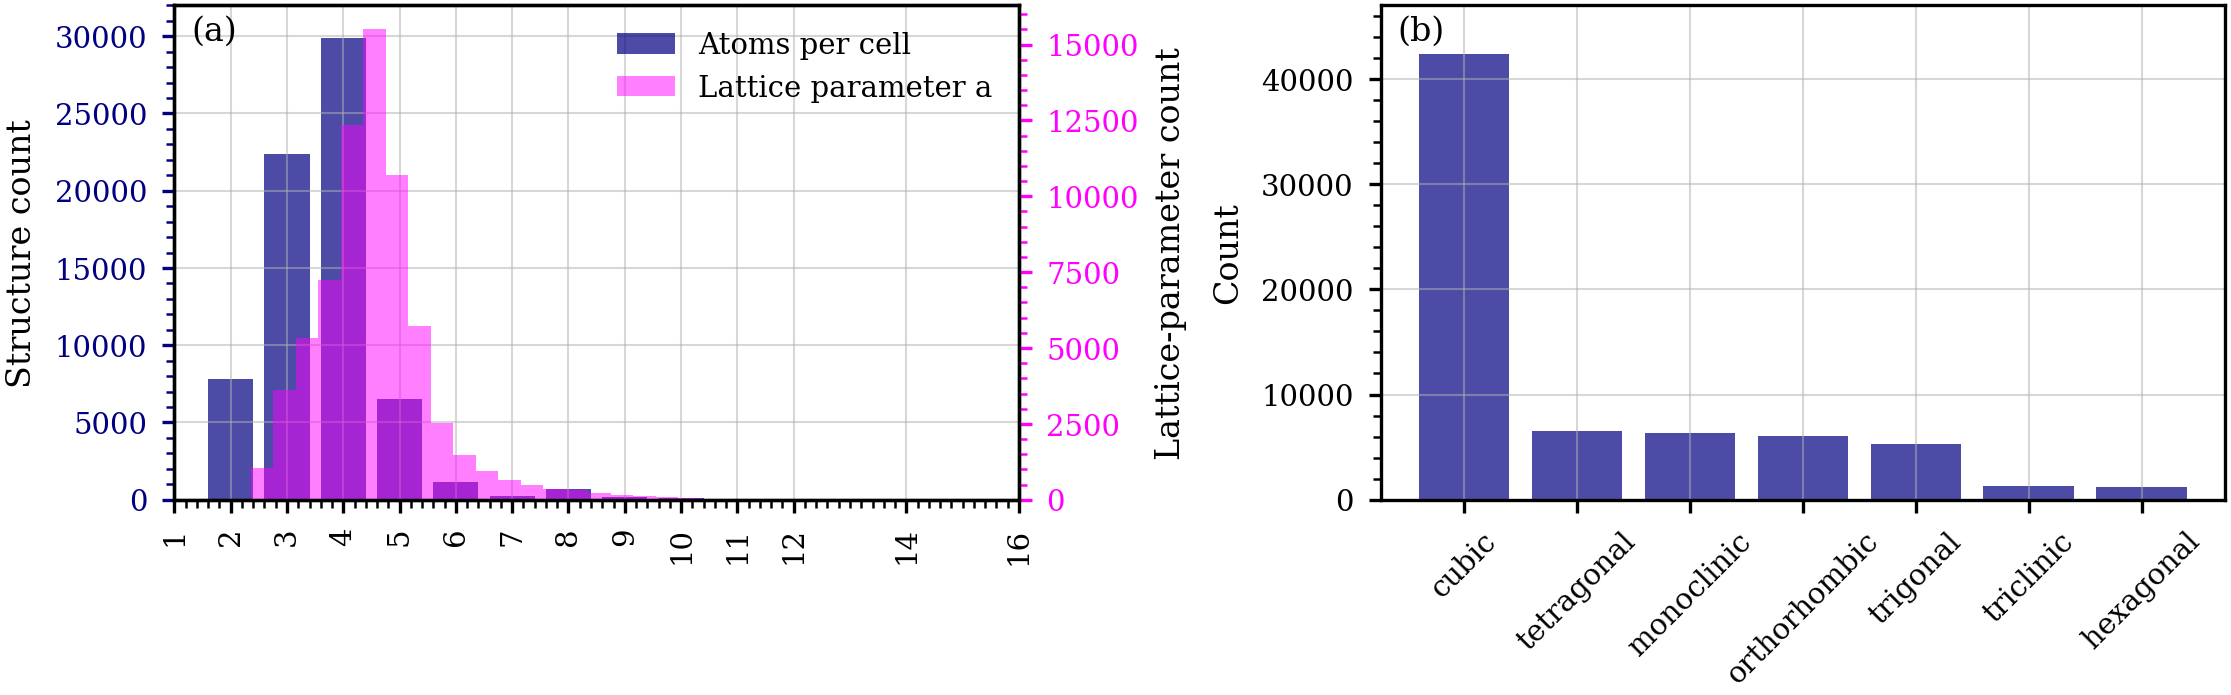

In [68]:
site_counts = structure_df["nsites"].value_counts().sort_index()
crystal_counts = structure_df["crystal_system"].value_counts()

set_publication_style()

fig, (ax_sites, ax_crystal) = plt.subplots(1, 2, constrained_layout=True)

ax_lattice = ax_sites.twinx()
ax_lattice.grid(False, which="both")
ax_sites.bar(site_counts.index, site_counts.values, color="navy", alpha=0.7, label="Atoms per cell")
ax_lattice.hist(structure_df["a"], bins=50, color="magenta", alpha=0.5, label="Lattice parameter a")
ax_sites.set(xlim=(1.5, 13), ylim=(0, 32000), ylabel="Structure count")
ax_sites.set_xticks(site_counts.index)
ax_sites.tick_params(axis="x", rotation=90)
ax_lattice.set_ylabel("Lattice-parameter count")
ax_sites.tick_params(axis="y", colors="navy", which="both")
ax_lattice.tick_params(axis="y", colors="magenta", which="both")
handles_1, labels_1 = ax_sites.get_legend_handles_labels()
handles_2, labels_2 = ax_lattice.get_legend_handles_labels()
ax_sites.legend(handles_1 + handles_2, labels_1 + labels_2)
ax_sites.text(0.02, 0.98, "(a)", transform=ax_sites.transAxes, va="top")

ax_crystal.bar(crystal_counts.index, crystal_counts.values, color="navy", alpha=0.7)
ax_crystal.set(ylim=(0, 47000), ylabel="Count")
ax_crystal.tick_params(axis="x", rotation=45)
ax_crystal.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax_crystal.text(0.02, 0.98, "(b)", transform=ax_crystal.transAxes, va="top")

fig.savefig("structure_distributions.pdf")
plt.show()

## Compositional diversity

### Element frequency
Percentage of structures that contain each element.

In [10]:
element_counts = structure_df["elements"].explode().value_counts()
element_percent = (100 * element_counts / len(structure_df)).to_dict()

fig = ptable_heatmap_plotly(element_percent, colorscale="Viridis", log=False)
fig.update_layout(
    title={"text": "Element Percentage Heatmap (%)", "x": 0.38, "y": 0.85, "xanchor": "center"}
)
fig.write_image("heatmap_element_percentage.pdf")
fig.show()

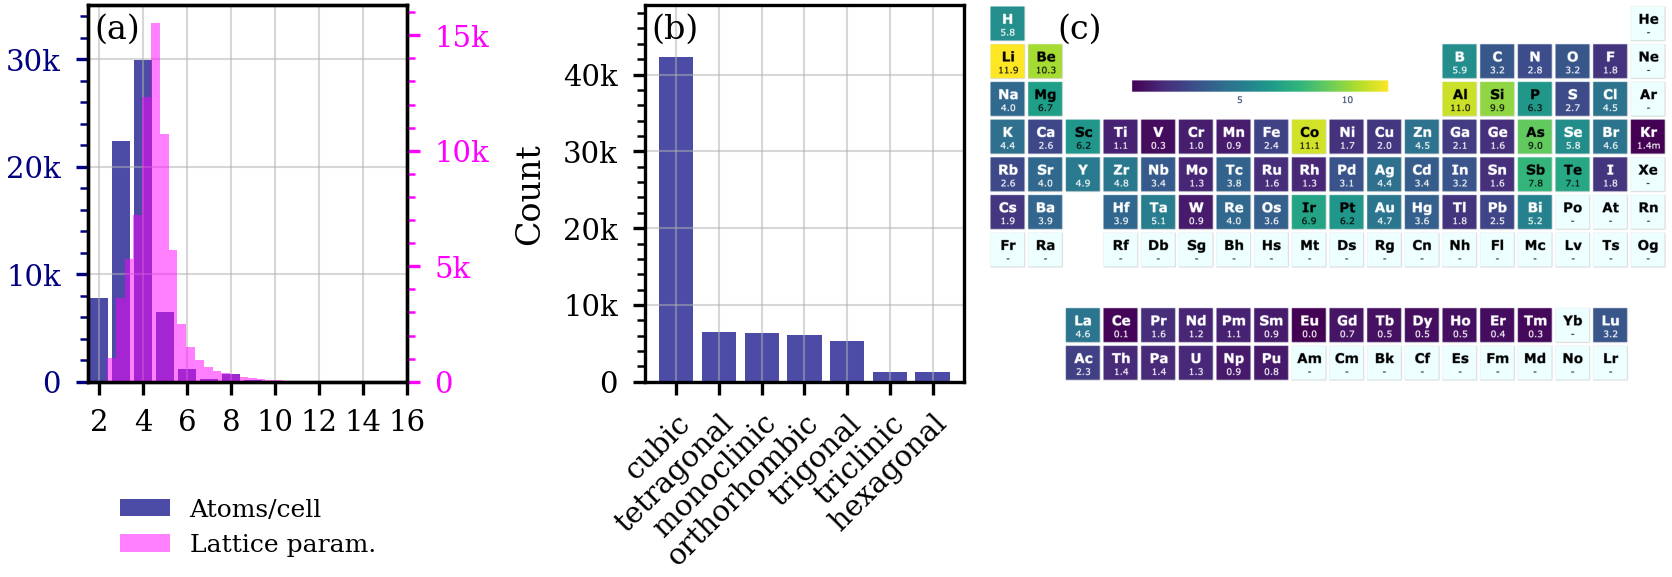

In [119]:
from io import BytesIO

import matplotlib.image as mpimg

set_publication_style()

site_counts = structure_df["nsites"].value_counts().sort_index()
crystal_counts = structure_df["crystal_system"].value_counts()
element_counts = structure_df["elements"].explode().value_counts()
element_percent = (100 * element_counts / len(structure_df)).to_dict()

# Render the Plotly periodic table (requires kaleido).
ptable_fig = ptable_heatmap_plotly(
    element_percent,
    colorscale="Viridis",
    log=False,
)

ptable_fig.update_layout(
    margin=dict(l=0, r=0, t=0, b=0),
    paper_bgcolor="white",
)

ptable_image = mpimg.imread(
    BytesIO(ptable_fig.to_image(format="png", scale=3)),
    format="png",
)

# Find non-white pixels, accounting for transparency.
rgb = ptable_image[..., :3]
if ptable_image.shape[-1] == 4:
    alpha = ptable_image[..., 3:4]
    rgb = rgb * alpha + (1 - alpha)

mask = np.any(rgb < 0.97, axis=-1)
rows, cols = np.where(mask)

if rows.size:
    pad = 8
    y0 = max(0, rows.min() - pad)
    y1 = min(ptable_image.shape[0], rows.max() + pad + 1)
    x0 = max(0, cols.min() - pad)
    x1 = min(ptable_image.shape[1], cols.max() + pad + 1)
    ptable_image = ptable_image[y0:y1, x0:x1]

# Total figure size: 18 × 6.5 cm.
cm = 1 / 2.54
fig, (ax_sites, ax_crystal, ax_ptable) = plt.subplots(
    1, 3,
    figsize=(18 * cm, 5 * cm),
    gridspec_kw={"width_ratios": [1, 1, 3.5]},
    constrained_layout=True,
)

# (a) Site counts and lattice parameter
ax_lattice = ax_sites.twinx()
ax_lattice.grid(False, which="both")

ax_sites.bar(
    site_counts.index, site_counts.values,
    color="navy", alpha=0.7, label="Atoms/cell",
)
ax_lattice.hist(
    structure_df["a"].dropna(),
    bins=50, color="magenta", alpha=0.5,
    label="Lattice param.",
)

ax_sites.set(
    xlim=(1.5, 13), ylim=(0, 35000),
    ylabel="Structure count",
)
ax_sites.set_xticks([2,4,6,8,10,12,14,16])
ax_sites.xaxis.set_minor_locator(mpl.ticker.NullLocator())
ax_sites.tick_params(axis="x")
ax_sites.tick_params(axis="y", colors="navy", which="both")
ax_sites.set_ylabel(None)

ax_lattice.tick_params(axis="y", colors="magenta", which="both")

handles_1, labels_1 = ax_sites.get_legend_handles_labels()
handles_2, labels_2 = ax_lattice.get_legend_handles_labels()

ax_sites.legend(
    handles_1 + handles_2,
    labels_1 + labels_2,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    fontsize=6,
    frameon=False,
)

# (b) Crystal systems
ax_crystal.bar(
    crystal_counts.index, crystal_counts.values,
    color="navy", alpha=0.7,
)
ax_crystal.set(ylim=(0, 49000), ylabel="Count")
ax_crystal.xaxis.set_minor_locator(mpl.ticker.NullLocator())

plt.setp(
    ax_crystal.get_xticklabels(),
    rotation=45, ha="right", rotation_mode="anchor",
)

# (c) Element percentages — display the cropped image.
ax_ptable.imshow(ptable_image, aspect="equal")
ax_ptable.set_anchor("W")
ax_ptable.set_axis_off()

# Panel labels
for ax, label in zip(
    (ax_sites, ax_crystal, ax_ptable), ("(a)", "(b)", "(c)")
):
    if label == "(a)" or label == "(b)":
        ax.text(
            0.02, 0.98, label,
            transform=ax.transAxes,
            ha="left", va="top",
        )
    if label == "(c)":
        ax.text(
            0.1, 0.98, label,
            transform=ax.transAxes,
            ha="left", va="top",
        )

from matplotlib.ticker import FuncFormatter

def format_thousands(value, pos):
    return f"{value / 1000:g}k" if abs(value) >= 1000 else f"{value:g}"

for ax in (ax_sites, ax_lattice, ax_crystal):
    ax.yaxis.set_major_formatter(FuncFormatter(format_thousands))

with mpl.rc_context({"savefig.bbox": None}):
    fig.savefig("structure_distributions_and_elements.pdf", dpi=300)

plt.show()

### Element co-occurrence

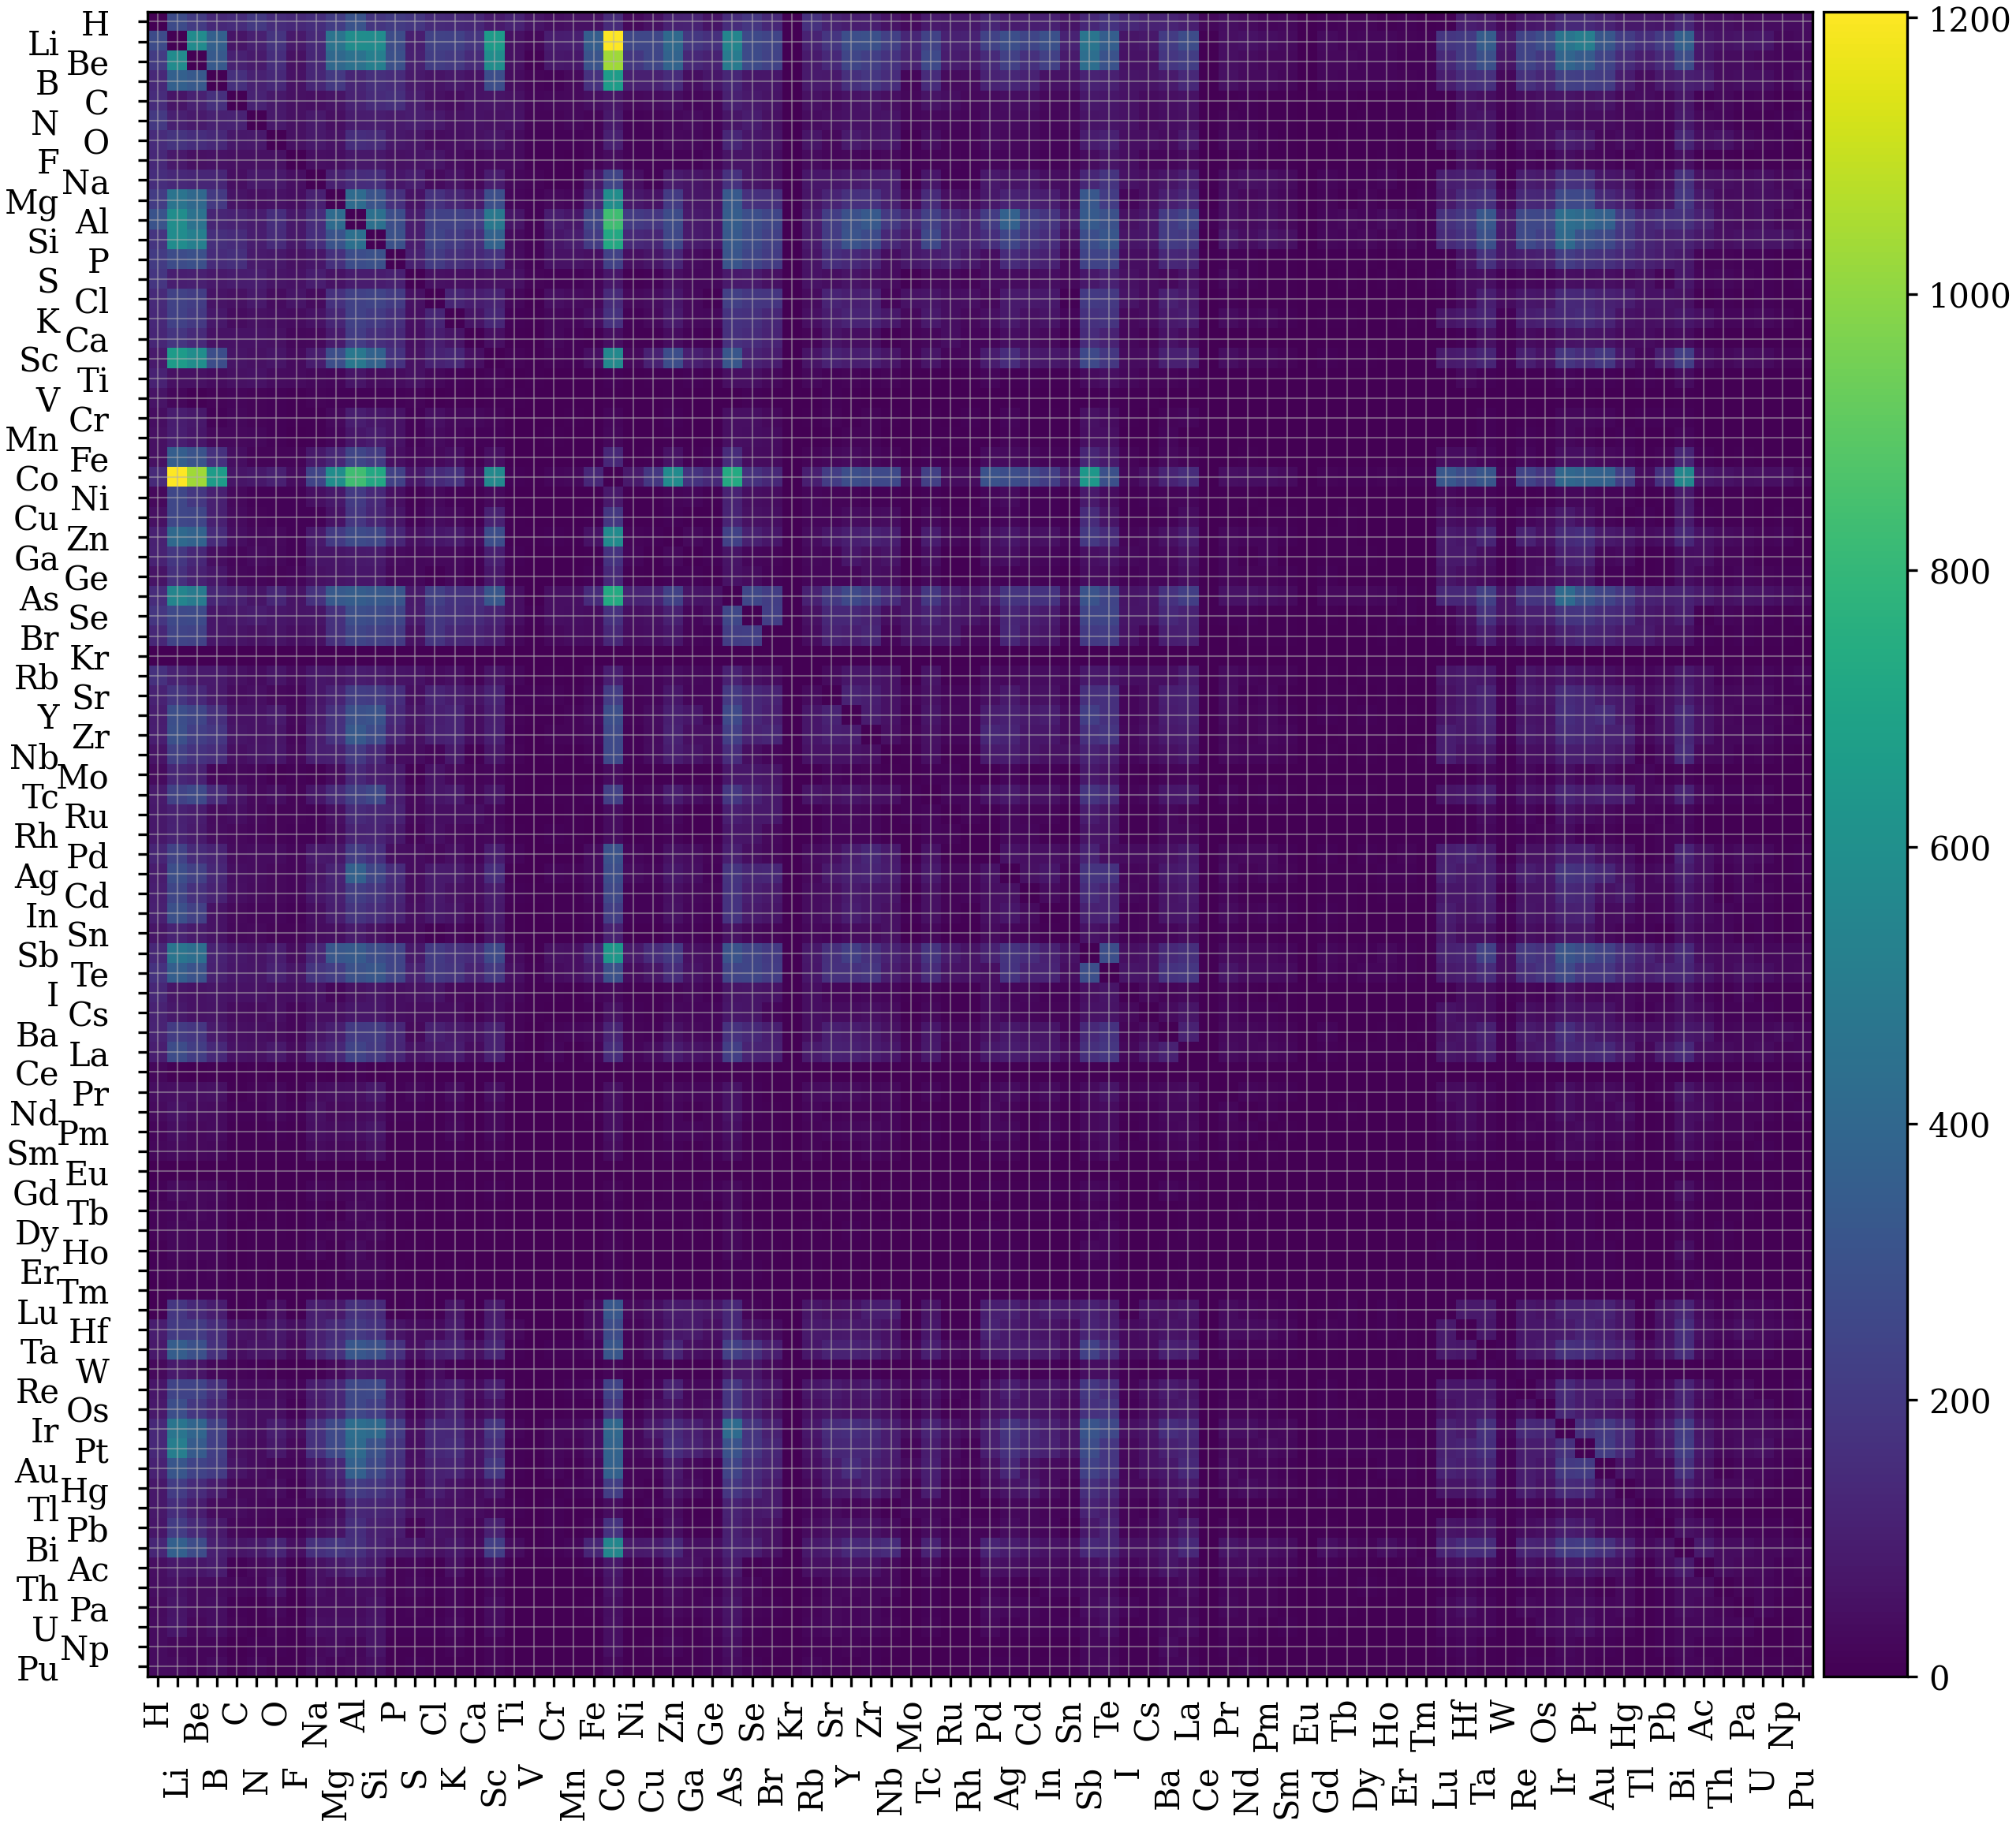

In [11]:
elements_list = sorted(element_counts.index, key=lambda symbol: Element(symbol).Z)
element_index = {symbol: i for i, symbol in enumerate(elements_list)}

cooccurrence = np.zeros((len(elements_list), len(elements_list)))
for elements in structure_df["elements"]:
    for e1, e2 in combinations(elements, 2):
        i, j = element_index[e1], element_index[e2]
        cooccurrence[i, j] += 1
        cooccurrence[j, i] += 1

# This large figure uses bigger fonts than the shared style.
with plt.rc_context(
    {
        "font.size": 12,
        "axes.labelsize": 14,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "xtick.minor.visible": False,
        "ytick.minor.visible": False,
    }
):
    fig, ax = plt.subplots(figsize=(10, 8))
    image = ax.imshow(cooccurrence)
    fig.colorbar(image, pad=0.005)
    ax.set_xticks(range(len(elements_list)), elements_list, rotation=90)
    ax.set_yticks(range(len(elements_list)), elements_list)

    # Stagger the tick labels so neighbouring elements do not overlap.
    for i, label in enumerate(ax.get_xticklabels()):
        label.set_y(0 if i % 2 == 0 else -0.04)
    for i, label in enumerate(ax.get_yticklabels()):
        label.set_x(-0.01 if i % 2 == 0 else -0.04)

    fig.tight_layout()
    fig.savefig("element_cooccurrence_heatmap.pdf")
    plt.show()

### Metallic-element sites
Percentage of sites in each structure occupied by a metal (pymatgen's `Element.is_metal`).

Structures included: 69,117/69,117
Metallic elements represented: Li, Be, Na, Mg, Al, K, Ca, Sc, Ti, V, Cr, Mn, Fe, Co, Ni, Cu, Zn, Ga, Rb, Sr, Y, Zr, Nb, Mo, Tc, Ru, Rh, Pd, Ag, Cd, In, Sn, Cs, Ba, La, Ce, Pr, Nd, Pm, Sm, Eu, Gd, Tb, Dy, Ho, Er, Tm, Lu, Hf, Ta, W, Re, Os, Ir, Pt, Au, Hg, Tl, Pb, Bi, Ac, Th, Pa, U, Np, Pu


,metal_site_percentage
count,69117.000000
mean,68.194357
std,29.782681
min,0.000000
25%,50.000000
50%,75.000000
75%,100.000000
max,100.000000


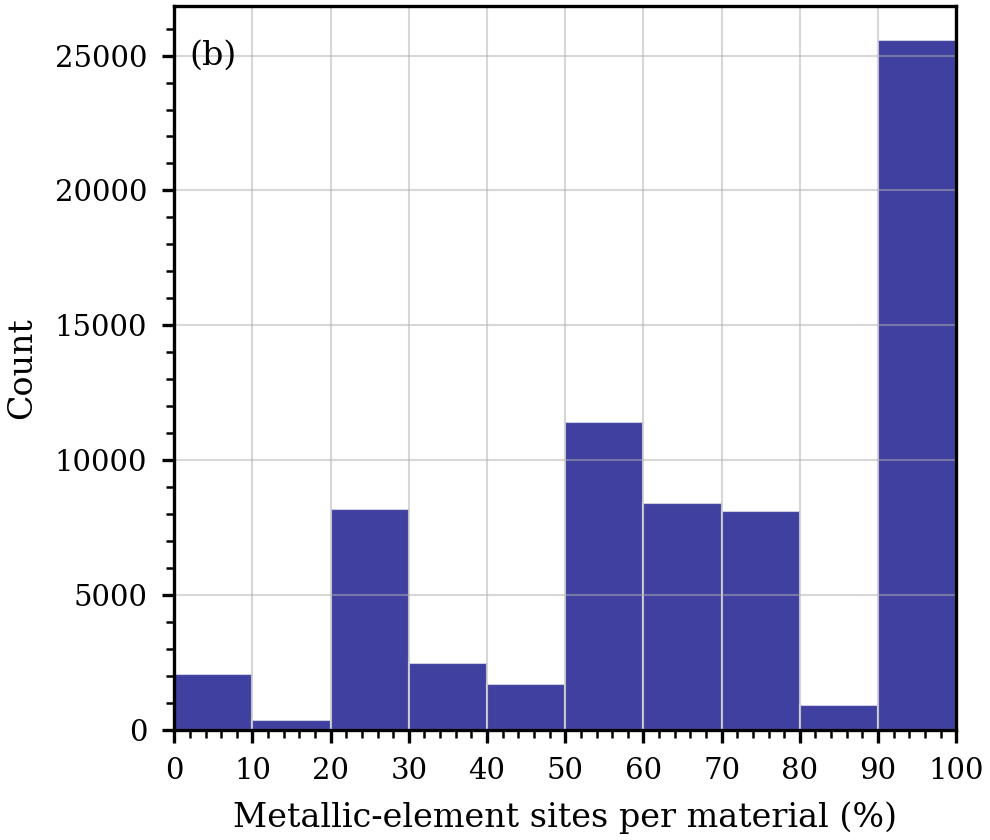

In [12]:
@lru_cache(maxsize=None)
def is_metal_element(symbol):
    return bool(Element(str(symbol)).is_metal)


species = df["species_at_sites"].dropna()
metal_percentages = 100 * species.map(lambda s: sum(map(is_metal_element, s)) / len(s))

metal_symbols = sorted(
    filter(is_metal_element, element_counts.index), key=lambda symbol: Element(symbol).Z
)
print(f"Structures included: {len(metal_percentages):,}/{len(df):,}")
print(f"Metallic elements represented: {', '.join(metal_symbols)}")
display(metal_percentages.describe().to_frame("metal_site_percentage"))

fig, ax = plt.subplots(figsize=(3.5, 3))
ax.hist(
    metal_percentages, bins=np.arange(0, 110, 10),
    color="navy", alpha=0.75, edgecolor="white", linewidth=0.5,
)
ax.text(5, 25000, "(b)", ha="center", va="center")
ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 10))
ax.set_xlabel("Metallic-element sites per material (%)")
ax.set_ylabel("Count")
fig.tight_layout()
fig.savefig("metal_site_percentage_distribution.pdf", dpi=300)
plt.show()

### SMACT validity

Each formula is screened with several SMACT option sets. All keep the default ICSD24 oxidation-state filtering.
"Charge neutrality only" drops the Pauling test, so it is a relaxed diagnostic rather than a recommended screen.

A higher pass rate does not make a rule better. Disabling the Pauling test weakens the chemical criterion, and a lower metallicity threshold makes the metallic exemption more permissive.

Running all seven option sets takes a few minutes.

In [13]:
DEFAULT_CONFIGURATION = "Default"
PRIMARY_CONFIGURATION = "Mixed + metallicity (0.7)"

SMACT_CONFIGURATIONS = {
    "Strict ionic": dict(use_pauling_test=True, include_alloys=False, check_metallicity=False, mixed_valence=False),
    "Default": dict(use_pauling_test=True, include_alloys=True, check_metallicity=False, mixed_valence=False),
    "Mixed valence": dict(use_pauling_test=True, include_alloys=True, check_metallicity=False, mixed_valence=True),
    "Metallicity (0.7)": dict(use_pauling_test=True, include_alloys=True, check_metallicity=True, metallicity_threshold=0.7, mixed_valence=False),
    "Mixed + metallicity (0.7)": dict(use_pauling_test=True, include_alloys=True, check_metallicity=True, metallicity_threshold=0.7, mixed_valence=True),
    "Mixed + metallicity (0.5)": dict(use_pauling_test=True, include_alloys=True, check_metallicity=True, metallicity_threshold=0.5, mixed_valence=True),
    "Charge neutrality only": dict(use_pauling_test=False, include_alloys=True, check_metallicity=True, metallicity_threshold=0.7, mixed_valence=True),
}

formulas = df["chemical_formula_reduced"].astype("string").str.strip()
unique_formulas = formulas.dropna().unique()

# One boolean column per configuration; <NA> where SMACT could not evaluate the formula.
smact_results = pd.DataFrame({"source": source}, index=df.index)
smact_errors = {}
for name, options in SMACT_CONFIGURATIONS.items():
    print(f"Evaluating {name} ...")
    lookup, errors = {}, {}
    # Evaluate each unique formula once.
    for formula in unique_formulas:
        try:
            lookup[formula] = bool(smact_validity(formula, **options))
        except (AttributeError, KeyError, TypeError, ValueError) as error:
            lookup[formula] = pd.NA
            errors[formula] = str(error)
    smact_results[name] = formulas.map(lookup).astype("boolean")
    smact_errors[name] = errors

print(f"SMACT version: {getattr(smact, '__version__', 'unknown')}")
print(f"Structures: {len(df):,}; unique formulas: {len(unique_formulas):,}")

Evaluating Strict ionic ...
Evaluating Default ...
Evaluating Mixed valence ...
Evaluating Metallicity (0.7) ...
Evaluating Mixed + metallicity (0.7) ...
Evaluating Mixed + metallicity (0.5) ...
Evaluating Charge neutrality only ...
SMACT version: 4.0.0
Structures: 69,117; unique formulas: 39,514


In [15]:
configurations = list(SMACT_CONFIGURATIONS)
results = smact_results[configurations]

# Unevaluated entries are excluded from the denominators.
evaluated = results.notna().sum()
valid = results.sum()
smact_summary = pd.DataFrame(
    {
        "valid": valid,
        "invalid": evaluated - valid,
        "not_evaluated": len(results) - evaluated,
        "evaluated": evaluated,
        "valid_percent": 100 * valid / evaluated,
    }
)
smact_summary["change_vs_default_pp"] = (
    smact_summary["valid_percent"] - smact_summary.loc[DEFAULT_CONFIGURATION, "valid_percent"]
)
display(smact_summary.round(3))

primary = smact_summary.loc[PRIMARY_CONFIGURATION]
print(
    f"Primary chemistry-aware configuration ({PRIMARY_CONFIGURATION}): "
    f"{int(primary['valid']):,}/{int(primary['evaluated']):,} evaluated structures valid "
    f"({primary['valid_percent']:.2f}%)."
)

error_counts = pd.Series({name: len(errors) for name, errors in smact_errors.items()})
if error_counts.sum() > 0:
    display(error_counts.to_frame("unevaluated_unique_formulas"))

# Valid percentage per configuration (rows) and source database (columns).
by_source = smact_results.groupby("source")[configurations]
score_table = (100 * by_source.sum() / by_source.count()).T
score_table

,valid,invalid,not_evaluated,evaluated,valid_percent,change_vs_default_pp
Strict ionic,4227,64890,0,69117,6.116,-41.318
Default,32785,36332,0,69117,47.434,0.0
Mixed valence,32789,36328,0,69117,47.44,0.006
Metallicity (0.7),36967,32150,0,69117,53.485,6.051
Mixed + metallicity (0.7),36971,32146,0,69117,53.49,6.056
Mixed + metallicity (0.5),53711,15406,0,69117,77.71,30.276
Charge neutrality only,37780,31337,0,69117,54.661,7.227


Primary chemistry-aware configuration (Mixed + metallicity (0.7)): 36,971/69,117 evaluated structures valid (53.49%).


source,agm,mp,oqmd
Strict ionic,8.020552,25.645439,3.22853
Default,32.816956,64.716007,66.309817
Mixed valence,32.827232,64.716007,66.309817
Metallicity (0.7),37.18176,66.26506,74.664821
Mixed + metallicity (0.7),37.192036,66.26506,74.664821
Mixed + metallicity (0.5),67.483622,76.247849,91.182331
Charge neutrality only,39.144509,66.609294,74.823545


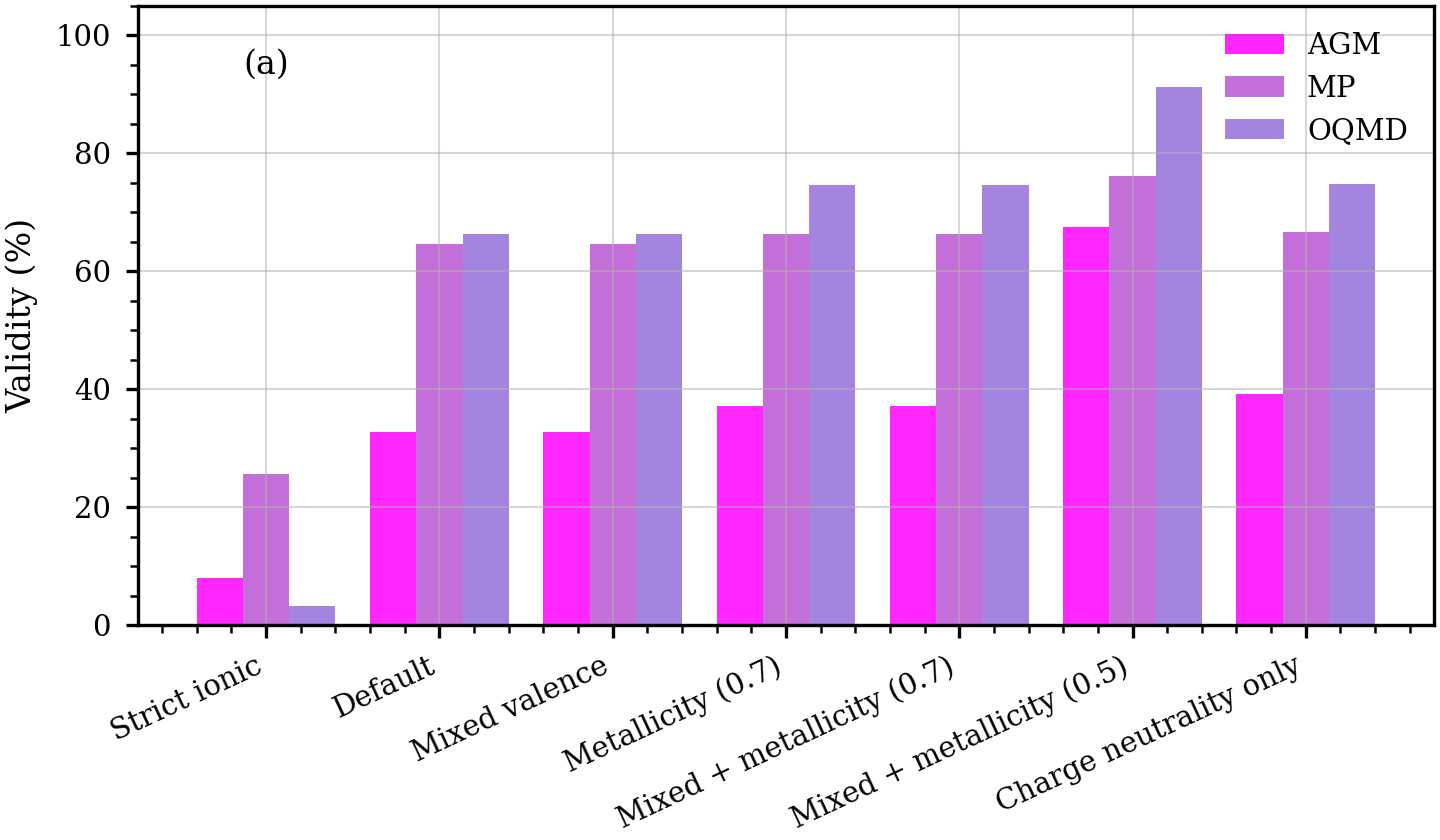

In [16]:
fig, ax = plt.subplots(figsize=(5, 3))
x_positions = np.arange(len(score_table))
sources = score_table.columns.tolist()
bar_width = 0.8 / len(sources)

for i, src in enumerate(sources):
    offset = (i - (len(sources) - 1) / 2) * bar_width
    ax.bar(
        x_positions + offset, score_table[src], width=bar_width,
        color=PURPLES[i % len(PURPLES)], alpha=0.85, label=src.upper(),
    )

ax.text(0.002, 95, "(a)", ha="center", va="center")
ax.set_xticks(x_positions, score_table.index, rotation=25, ha="right")
ax.set_ylabel("Validity (%)")
ax.set_ylim(0, 105)
ax.legend()
fig.tight_layout()
fig.savefig("smact_validity_option_comparison.pdf", dpi=300)
plt.show()

## Comparative PCA: structure, charge density and Bader charge

Four standardised PCAs are calculated from the same baseline descriptors (size, lattice, composition fractions, one-hot space group), optionally extended with charge-density and/or Bader-charge statistics.
With `USE_COMMON_ROWS = True`, all four use the same structures so their projections and explained variances are directly comparable.

Parsing the charge densities is slow; set `PCA_SAMPLE_SIZE` (e.g. `10_000`) for a quicker run.

In [17]:
PCA_SAMPLE_SIZE = None
PCA_RANDOM_STATE = 42
USE_COMMON_ROWS = True

analysis_df = df
if PCA_SAMPLE_SIZE is not None and PCA_SAMPLE_SIZE < len(df):
    analysis_df = df.sample(PCA_SAMPLE_SIZE, random_state=PCA_RANDOM_STATE)


def parse_array(value):
    # Return the finite values of a (possibly string-encoded) array, or None if missing/unparseable.
    if value is None or value is pd.NA or (isinstance(value, float) and np.isnan(value)):
        return None
    try:
        array = flatten_numeric(ast.literal_eval(value) if isinstance(value, str) else value)
    except (SyntaxError, ValueError, TypeError, OverflowError):
        return None
    array = array[np.isfinite(array)]
    return array if array.size else None


DENSITY_NAMES = ["rho_mean", "rho_std", "rho_min", "rho_q05", "rho_q25", "rho_median",
                 "rho_q75", "rho_q95", "rho_max", "rho_abs_mean", "rho_rms"]
BADER_NAMES = ["bader_mean", "bader_std", "bader_min", "bader_q25", "bader_median",
               "bader_q75", "bader_max", "bader_range", "bader_abs_mean", "bader_sum"]


def density_features(value):
    rho = parse_array(value)
    if rho is None:
        return pd.Series(np.nan, index=DENSITY_NAMES)
    q05, q25, median, q75, q95 = np.quantile(rho, [0.05, 0.25, 0.50, 0.75, 0.95])
    return pd.Series(
        [rho.mean(), rho.std(), rho.min(), q05, q25, median, q75, q95, rho.max(),
         np.abs(rho).mean(), np.sqrt(np.mean(rho**2))],
        index=DENSITY_NAMES,
    )


def bader_features(value):
    q = parse_array(value)
    if q is None:
        return pd.Series(np.nan, index=BADER_NAMES)
    q25, median, q75 = np.quantile(q, [0.25, 0.50, 0.75])
    return pd.Series(
        [q.mean(), q.std(), q.min(), q25, median, q75, q.max(), np.ptp(q),
         np.abs(q).mean(), q.sum()],
        index=BADER_NAMES,
    )


# Baseline: size, lattice geometry, composition fractions and one-hot space group.
baseline_numeric = (
    analysis_df[["nsites", "nelements", "nperiodic_dimensions"]]
    .apply(pd.to_numeric, errors="coerce")
    .join(lattice_df.loc[analysis_df.index].add_prefix("lattice_"))
)
composition_df = pd.DataFrame(
    [
        {f"fraction_{el}": n / len(s) for el, n in Counter(map(str, s)).items()}
        if s is not None and len(s) else {}
        for s in analysis_df["species_at_sites"]
    ],
    index=analysis_df.index,
).fillna(0.0).sort_index(axis=1)
space_group_df = pd.get_dummies(
    analysis_df["space_group_it_number"].astype("Int64").astype(str),
    prefix="space_group",
    dtype=float,
)
baseline_df = pd.concat([baseline_numeric, composition_df, space_group_df], axis=1)

density_df = analysis_df["compressed_charge_density"].apply(density_features)
bader_df = analysis_df["bader_charges"].apply(bader_features)
# Approximate integral of the density over the cell; valid when rho is in e/Å³.
density_df["rho_integral_proxy"] = density_df["rho_mean"] * baseline_df["lattice_volume"]

feature_groups = {
    "Baseline": baseline_df,
    "+ Charge density": pd.concat([baseline_df, density_df], axis=1),
    "+ Bader charges": pd.concat([baseline_df, bader_df], axis=1),
    "+ Density + Bader": pd.concat([baseline_df, density_df, bader_df], axis=1),
}


def calculate_pca(features, row_mask):
    matrix = features.loc[row_mask].dropna(axis=0)
    # Drop constant columns; they carry no information after standardisation.
    matrix = matrix.loc[:, matrix.nunique(dropna=False) > 1]
    if len(matrix) < 2 or matrix.shape[1] < 2:
        raise ValueError(f"PCA needs at least two rows and two varying features; got {matrix.shape}.")

    model = PCA(n_components=2, random_state=PCA_RANDOM_STATE)
    scores = model.fit_transform(StandardScaler().fit_transform(matrix))
    return {
        "model": model,
        "scores": pd.DataFrame(scores, index=matrix.index, columns=["PC1", "PC2"]),
        "loadings": pd.DataFrame(model.components_.T, index=matrix.columns, columns=["PC1", "PC2"]),
    }


feature_groups = {name: f.replace([np.inf, -np.inf], np.nan) for name, f in feature_groups.items()}
common_rows = feature_groups["+ Density + Bader"].notna().all(axis=1)

pca_results = {
    name: calculate_pca(features, common_rows if USE_COMMON_ROWS else features.notna().all(axis=1))
    for name, features in feature_groups.items()
}

comparison = pd.DataFrame(
    {
        name: {
            "structures": len(result["scores"]),
            "features": len(result["loadings"]),
            "PC1 variance (%)": 100 * result["model"].explained_variance_ratio_[0],
            "PC2 variance (%)": 100 * result["model"].explained_variance_ratio_[1],
            "PC1 + PC2 (%)": 100 * result["model"].explained_variance_ratio_.sum(),
        }
        for name, result in pca_results.items()
    }
).T
comparison.round(2)

,structures,features,PC1 variance (%),PC2 variance (%),PC1 + PC2 (%)
Baseline,59613.0,187.0,2.14,1.70,3.84
+ Charge density,59613.0,199.0,3.23,2.37,5.60
+ Bader charges,59613.0,197.0,3.09,2.02,5.11
+ Density + Bader,59613.0,209.0,3.09,2.93,6.02


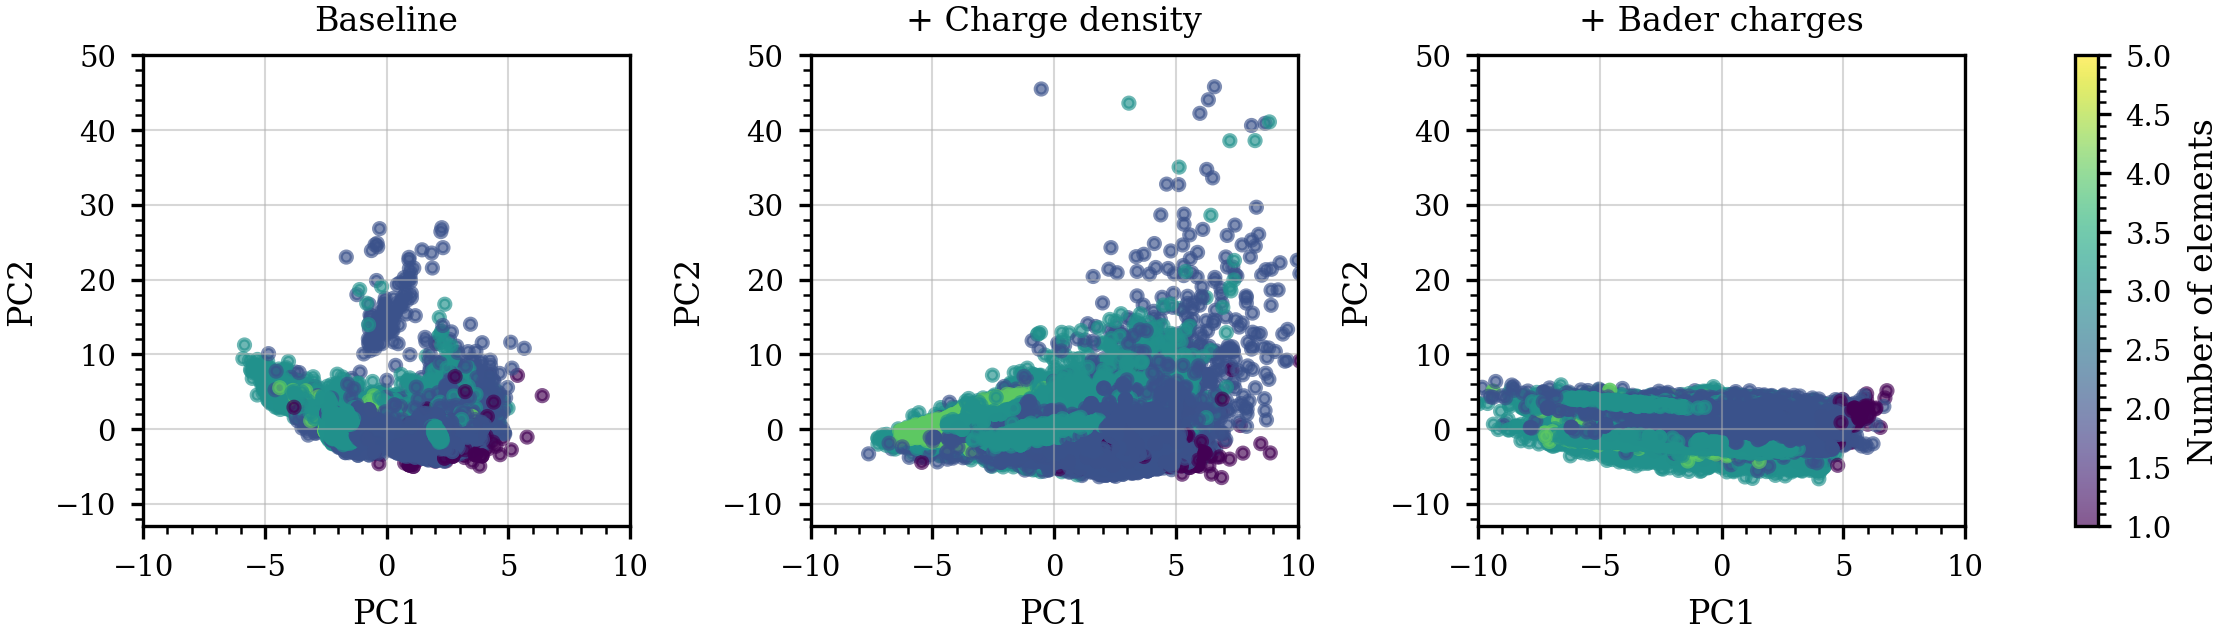

,PC1,PC2
rho_rms,0.348891,0.079423
rho_std,0.343913,0.072849
rho_max,0.293434,0.078457
rho_q95,0.273989,0.014231
rho_abs_mean,0.272286,0.079218
rho_mean,0.272286,0.079218
rho_integral_proxy,0.267188,0.099838
lattice_volume,0.251396,0.103116
lattice_a,0.215007,0.064440
lattice_b,0.205674,0.064910


In [131]:
# PCA signs are arbitrary; rotate/flip panels so the four projections share an orientation.
PANEL_ORIENTATION = {
    "Baseline": lambda pc1, pc2: (pc1, pc2),
    "+ Charge density": lambda pc1, pc2: (-pc2, pc1),
    "+ Bader charges": lambda pc1, pc2: (-pc1, pc2),
}

set_publication_style()
cm = 1 / 2.54

fig, axes = plt.subplots(1, 3, figsize=(19 * cm, 5.5 * cm), constrained_layout=True)
for ax, (name, result) in zip(axes.flat, pca_results.items()):
    scores = result["scores"]
    variance = 100 * result["model"].explained_variance_ratio_
    x, y = PANEL_ORIENTATION[name](scores["PC1"], scores["PC2"])
    scatter = ax.scatter(
        x, y, c=analysis_df.loc[scores.index, "nelements"],
        cmap="viridis", s=7, alpha=0.65, rasterized=True,
    )
    ax.set_title(name)
    ax.set_xlabel(f"PC1")
    ax.set_ylabel(f"PC2")
    ax.set_xlim(-10, 10)
    ax.set_ylim(-13, 50)


fig.colorbar(scatter, ax=axes.ravel().tolist(), label="Number of elements", shrink=1)
fig.savefig("pca_charge_density_bader_comparison.pdf", dpi=300)
plt.show()

# Largest absolute loadings in the combined PCA.
pca_results["+ Density + Bader"]["loadings"].abs().sort_values("PC1", ascending=False).head(15)

## Bader-charge distributions

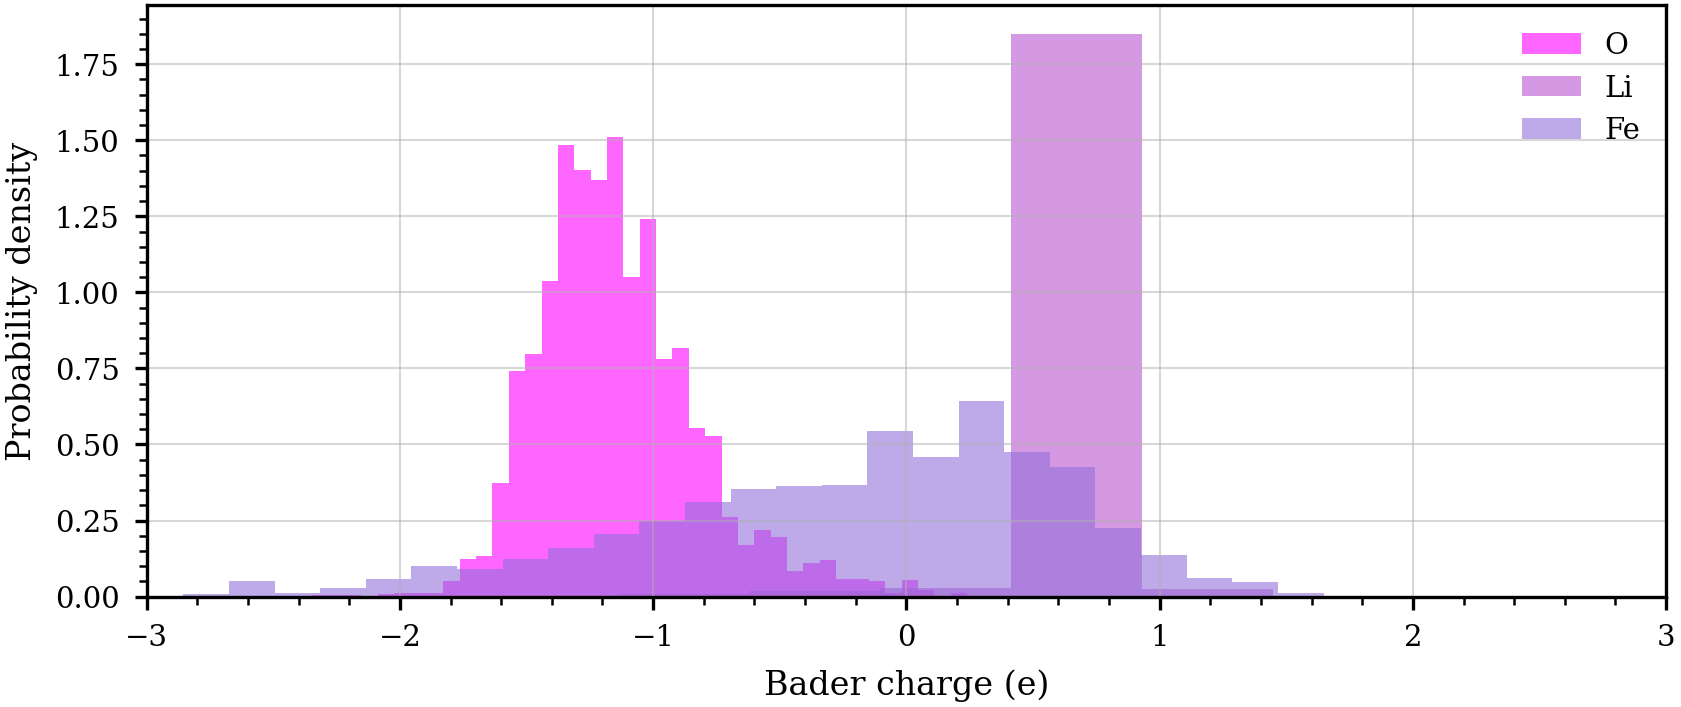

In [19]:
# Grid layout (row-major): transition metals, alkali metals and chalcogens in columns.
GRID_ELEMENTS = ["Fe", "Li", "O",
                 "Co", "Na", "S",
                 "Ni", "K", "Se"]

element_charges = {element: [] for element in GRID_ELEMENTS}
for species_list, charges in zip(df["species_at_sites"], df["bader_charges"]):
    if species_list is None or charges is None:
        continue
    for element, charge in zip(species_list, charges):
        if element in element_charges and charge is not None:
            element_charges[element].append(float(charge))
element_charges = {element: np.asarray(values) for element, values in element_charges.items()}

fig, ax = plt.subplots()
for element, color in zip(["O", "Li", "Fe"], PURPLES):
    ax.hist(element_charges[element], bins=40, density=True, alpha=0.6, label=element, color=color)
ax.set(xlim=(-3, 3), xlabel="Bader charge (e)", ylabel="Probability density")
ax.legend()
fig.savefig("bader_charge_histogram.pdf")
plt.show()

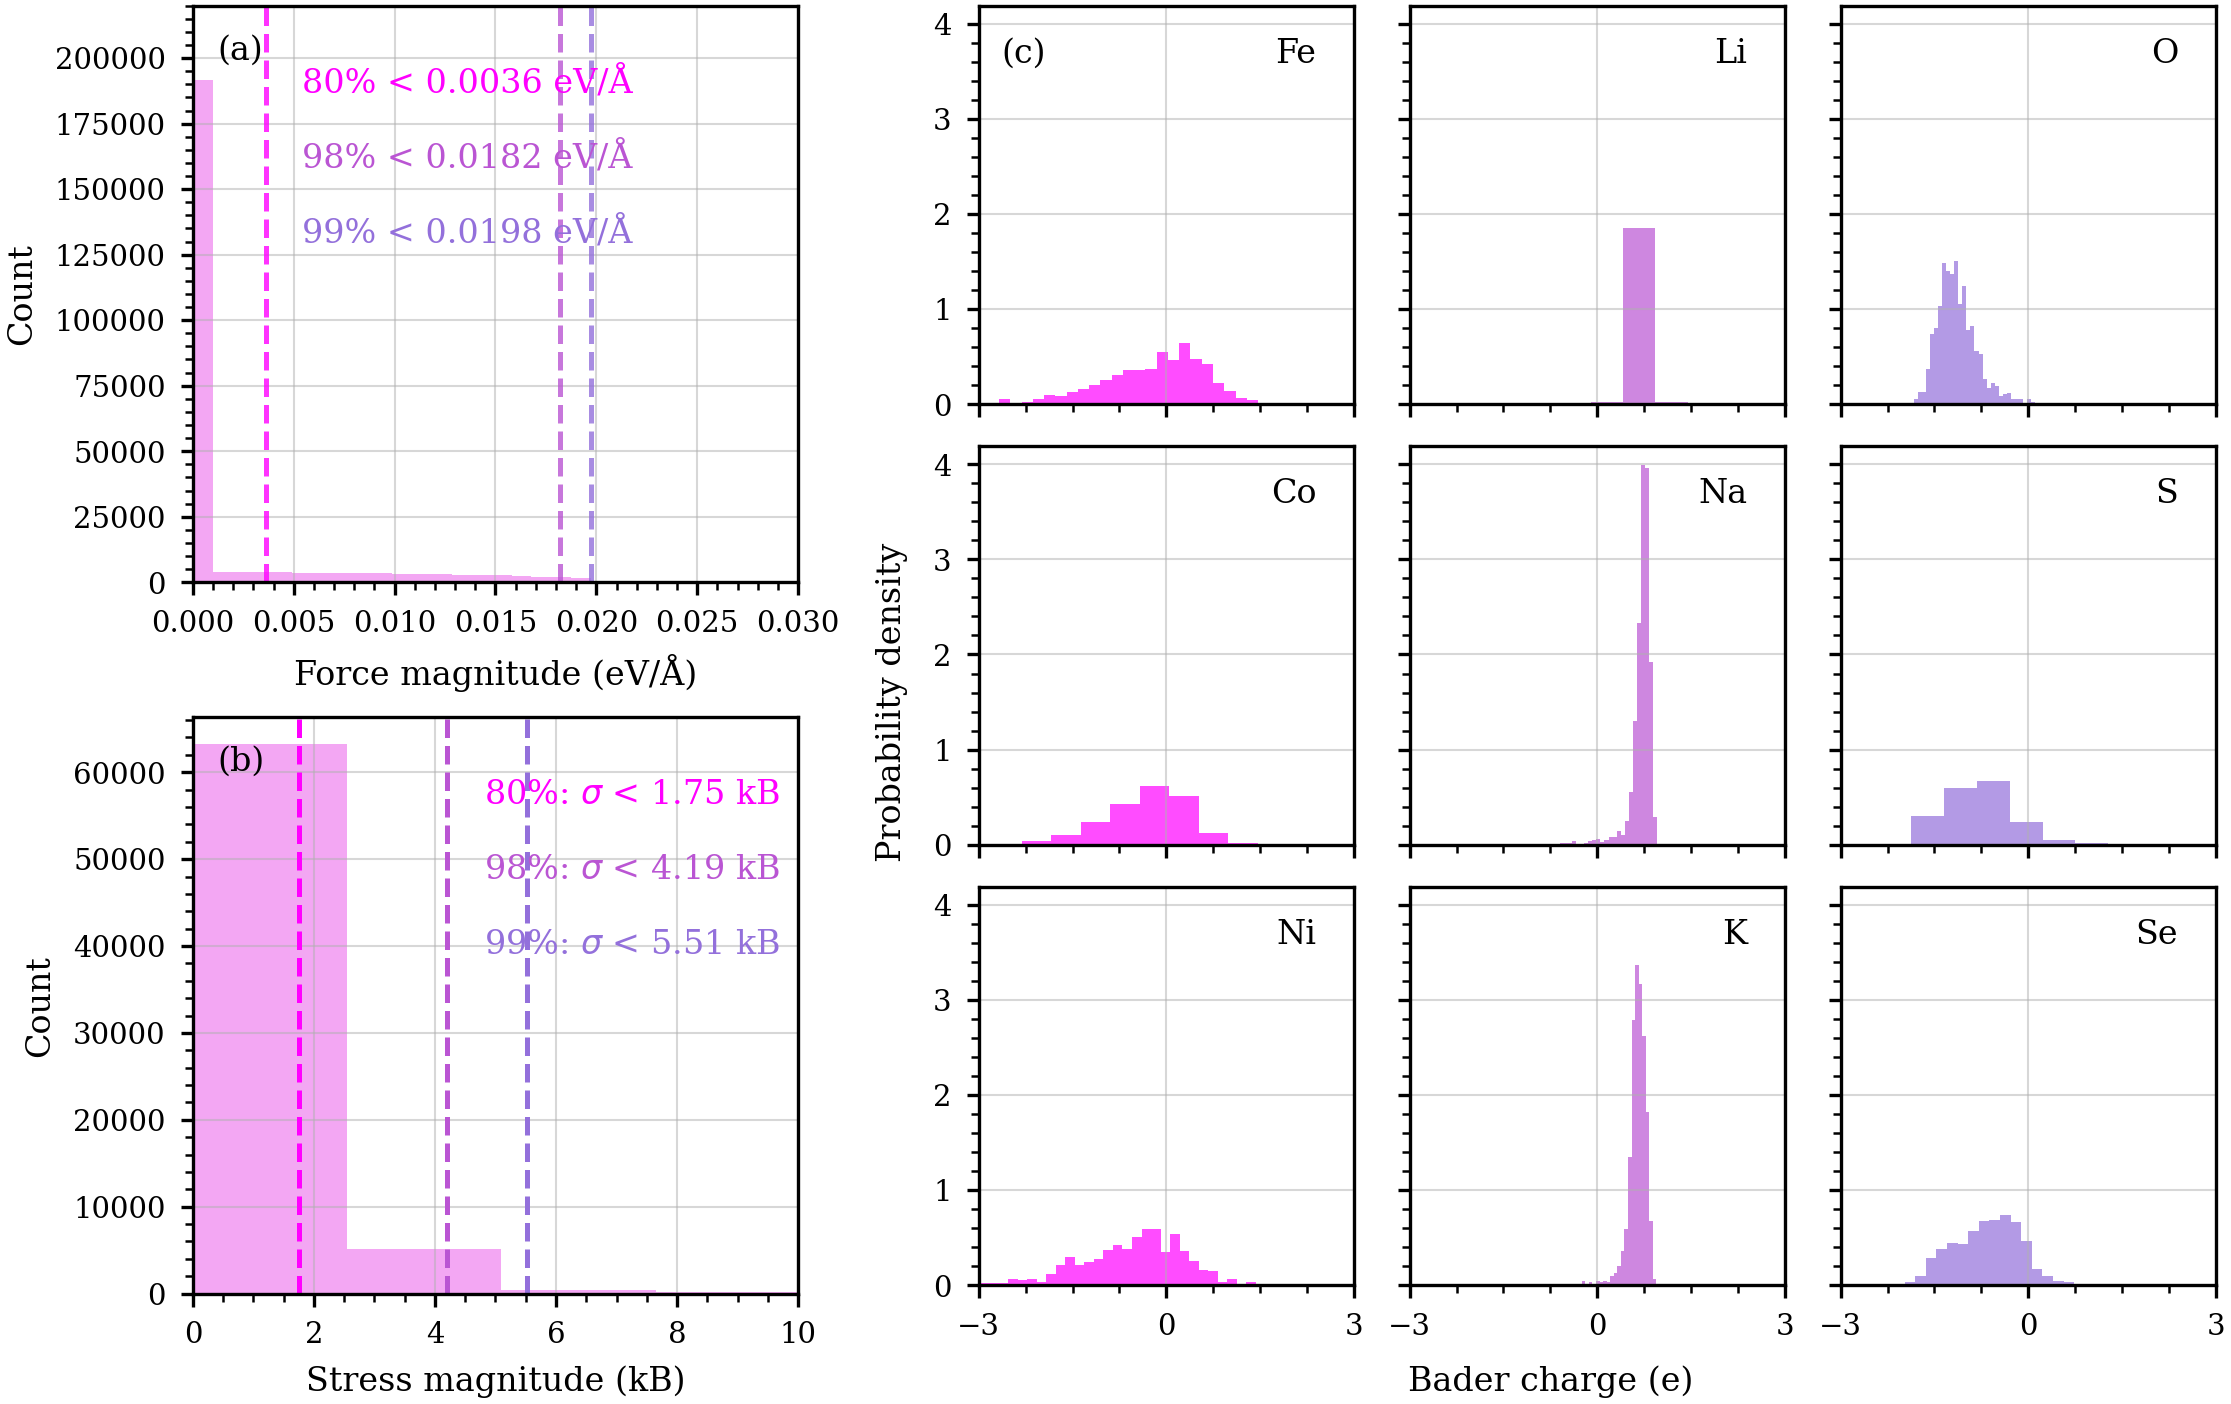

In [132]:
set_publication_style()

cm = 1 / 2.54

fig = plt.figure(constrained_layout=True, figsize=(19 * cm, 12 * cm))

left, right = fig.subfigures(
    1, 2, width_ratios=(1, 1.6), wspace=0.01
)

ax_force, ax_stress = left.subplots(2, 1)
axes_charge = right.subplots(3, 3, sharex=True, sharey=True)

# (a) Force magnitude
ax_force.hist(
    force_magnitude, bins=100, color="violet", alpha=0.7
)

for y, percentile, color in zip(
    (0.85, 0.72, 0.59), (80, 98, 99), PURPLES
):
    value = np.percentile(force_magnitude, percentile)
    ax_force.axvline(value, color=color, linestyle="--", alpha=0.8)
    ax_force.text(
        0.18, y, f"{percentile}% < {value:.4f} eV/Å",
        transform=ax_force.transAxes, color=color,
    )

ax_force.set(
    xlim=(0, 0.03),
    ylim=(0, 220000),
    xlabel="Force magnitude (eV/Å)",
    ylabel="Count",
)

# (b) Stress magnitude
ax_stress.hist(
    stress_magnitude, bins=60, color="violet", alpha=0.7
)

for y, percentile, color in zip(
    (0.85, 0.72, 0.59), (80, 98, 99), PURPLES
):
    value = np.percentile(stress_magnitude, percentile)
    ax_stress.axvline(value, color=color, linestyle="--")
    ax_stress.text(
        0.97, y, rf"{percentile}%: $\sigma$ < {value:.2f} kB",
        transform=ax_stress.transAxes, color=color, ha="right",
    )

ax_stress.set(
    xlim=(0, 10),
    xlabel="Stress magnitude (kB)",
    ylabel="Count",
)

for ax, label in zip((ax_force, ax_stress), ("(a)", "(b)")):
    ax.text(
        0.04, 0.95, label,
        transform=ax.transAxes, ha="left", va="top",
    )

# (c) Bader-charge distributions
grid_colors = {
    "Fe": "fuchsia", "Co": "fuchsia", "Ni": "fuchsia",
    "Li": "mediumorchid", "Na": "mediumorchid", "K": "mediumorchid",
    "O": "mediumpurple", "S": "mediumpurple", "Se": "mediumpurple",
}

for ax, element in zip(axes_charge.flat, GRID_ELEMENTS):
    ax.hist(
        element_charges[element],
        bins=40,
        density=True,
        color=grid_colors[element],
        alpha=0.7,
    )
    ax.text(
        0.90, 0.92, element,
        transform=ax.transAxes, ha="right", va="top",
    )
    ax.set_xlim(-3, 3)
    ax.set_xticks([-3, 0, 3])
    ax.label_outer()

axes_charge[0, 0].text(
    0.06, 0.92, "(c)",
    transform=axes_charge[0, 0].transAxes,
    ha="left", va="top",
)

right.supxlabel("Bader charge (e)", fontsize=mpl.rcParams["axes.labelsize"])
right.supylabel("Probability density", fontsize=mpl.rcParams["axes.labelsize"])

# Preserve the specified physical dimensions.
with mpl.rc_context({"savefig.bbox": None}):
    fig.savefig("force_stress_bader.pdf", dpi=300)

plt.show()

### Exploratory: effective radius from Bader volumes
Effective radius taken as $V^{1/3}$ of each atom's Bader volume.

,radius_mean,radius_std,count
element,,,
Al,2.495080,0.511638,9710
Li,1.628373,0.362261,10021
O,2.379649,0.327092,3731


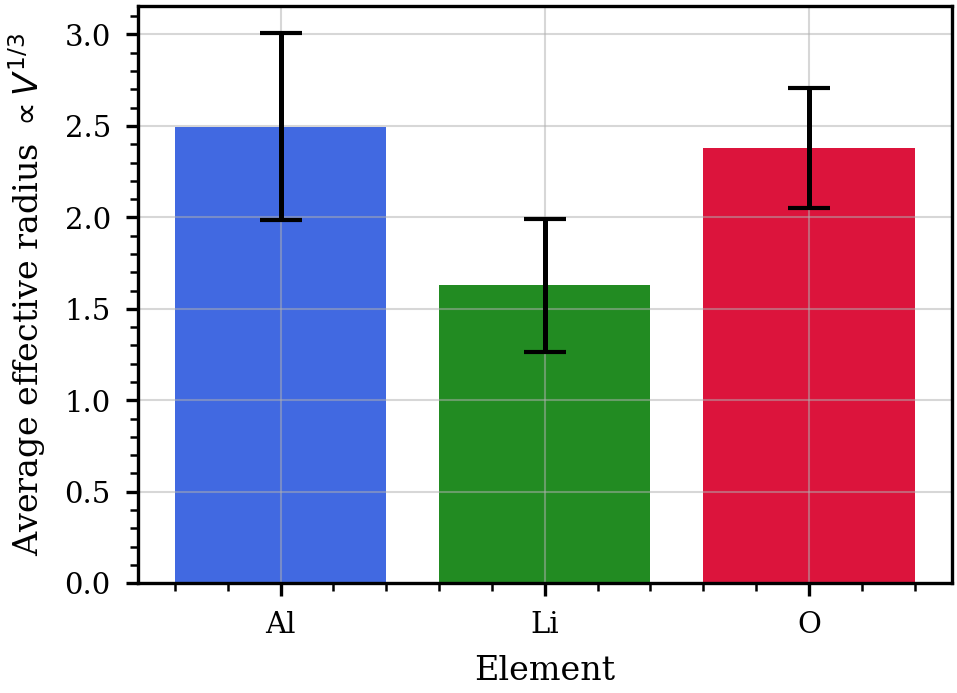

In [21]:
RADIUS_ELEMENTS = ["O", "Al", "Li"]

radius_rows = []
for species_list, volumes in zip(df["species_at_sites"], df["bader_atomic_volume"]):
    if species_list is None or volumes is None or len(species_list) != len(volumes):
        continue
    for element, volume in zip(map(str, species_list), volumes):
        if element in RADIUS_ELEMENTS and volume is not None:
            radius_rows.append({"element": element, "radius": float(volume) ** (1 / 3)})

radius_summary = (
    pd.DataFrame(radius_rows)
    .groupby("element")["radius"]
    .agg(radius_mean="mean", radius_std="std", count="count")
)
display(radius_summary)

fig, ax = plt.subplots(figsize=(3.5, 2.5))
ax.bar(
    radius_summary.index, radius_summary["radius_mean"], yerr=radius_summary["radius_std"],
    capsize=5, color=radius_summary.index.map({"O": "crimson", "Al": "royalblue", "Li": "forestgreen"}),
)
ax.set(xlabel="Element", ylabel=r"Average effective radius $\propto V^{1/3}$")
plt.show()